In [1]:
import pandas as pd

# 1. Create data
data = {
    "Order_ID": [1,2,3,4,5,6,7,8,9,10,10],
    "Product": [
        "Laptop","Phone","Headphones","Laptop"," phone ",
        "Mouse","Keyboard","PHONE","Laptop","Mouse","Mouse"
    ],
    "Quantity": [2,1,3,1,None,4,2,1,2,3,3],
    "Price": [50000,30000,2000,50000,30000,800,1500,30000,50000,800,800],
    "Region": [
        "South","North","East","South","North",
        "West","South","North","East","West","West"
    ]
}

df = pd.DataFrame(data)

# 2. Inspect data
print("ORIGINAL DATASET")
display(df)

print("\nDATASET STRUCTURE")
print(df.info())

# 3. Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 4. Check duplicates
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

# 5. Check consistency
print("\nUNIQUE PRODUCT VALUES BEFORE CLEANING")
print(df["Product"].unique())

# 6. Clean text
df["Product"] = df["Product"].str.strip().str.title()
df["Region"] = df["Region"].str.strip().str.title()

# 7. Handle missing values
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())

# 8. Remove duplicates
df = df.drop_duplicates()

# 9. Correct data types
df["Quantity"] = df["Quantity"].astype(int)
df["Price"] = df["Price"].astype(float)

# 10. Check cleaned data
print("\nAFTER CLEANING")
display(df)

print("\nMISSING VALUES AFTER CLEANING")
print(df.isnull().sum())

print("\nDUPLICATES AFTER CLEANING")
print(df.duplicated().sum())

print("\nDATA TYPES AFTER CLEANING")
print(df.dtypes)

# 11. Save cleaned data
df.to_csv("cleaned_sales_data.csv", index=False)

print("\nTASK 1 COMPLETED SUCCESSFULLY!")
print("Cleaned dataset saved as cleaned_sales_data.csv")

ORIGINAL DATASET


,Order_ID,Product,Quantity,Price,Region
0,1,Laptop,2.0,50000,South
1,2,Phone,1.0,30000,North
2,3,Headphones,3.0,2000,East
3,4,Laptop,1.0,50000,South
4,5,phone,NaN,30000,North
5,6,Mouse,4.0,800,West
6,7,Keyboard,2.0,1500,South
7,8,PHONE,1.0,30000,North
8,9,Laptop,2.0,50000,East
9,10,Mouse,3.0,800,West



DATASET STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  11 non-null     int64  
 1   Product   11 non-null     object 
 2   Quantity  10 non-null     float64
 3   Price     11 non-null     int64  
 4   Region    11 non-null     object 
dtypes: float64(1), int64(2), object(2)
memory usage: 572.0+ bytes
None

MISSING VALUES
Order_ID    0
Product     0
Quantity    1
Price       0
Region      0
dtype: int64

DUPLICATE RECORDS
1

UNIQUE PRODUCT VALUES BEFORE CLEANING
['Laptop' 'Phone' 'Headphones' ' phone ' 'Mouse' 'Keyboard' 'PHONE']

AFTER CLEANING


,Order_ID,Product,Quantity,Price,Region
0,1,Laptop,2,50000.0,South
1,2,Phone,1,30000.0,North
2,3,Headphones,3,2000.0,East
3,4,Laptop,1,50000.0,South
4,5,Phone,2,30000.0,North
5,6,Mouse,4,800.0,West
6,7,Keyboard,2,1500.0,South
7,8,Phone,1,30000.0,North
8,9,Laptop,2,50000.0,East
9,10,Mouse,3,800.0,West



MISSING VALUES AFTER CLEANING
Order_ID    0
Product     0
Quantity    0
Price       0
Region      0
dtype: int64

DUPLICATES AFTER CLEANING
0

DATA TYPES AFTER CLEANING
Order_ID      int64
Product      object
Quantity      int64
Price       float64
Region       object
dtype: object

TASK 1 COMPLETED SUCCESSFULLY!
Cleaned dataset saved as cleaned_sales_data.csv


In [2]:
# TASK 2- EDA

import pandas as pd

# Load cleaned data
df = pd.read_csv("cleaned_sales_data.csv")

print("DATASET")
display(df)

# Descriptive statistics
print("\nDESCRIPTIVE STATISTICS")
print(df.describe())

DATASET


,Order_ID,Product,Quantity,Price,Region
0,1,Laptop,2,50000.0,South
1,2,Phone,1,30000.0,North
2,3,Headphones,3,2000.0,East
3,4,Laptop,1,50000.0,South
4,5,Phone,2,30000.0,North
5,6,Mouse,4,800.0,West
6,7,Keyboard,2,1500.0,South
7,8,Phone,1,30000.0,North
8,9,Laptop,2,50000.0,East
9,10,Mouse,3,800.0,West



DESCRIPTIVE STATISTICS
       Order_ID   Quantity         Price
count  10.00000  10.000000     10.000000
mean    5.50000   2.100000  24510.000000
std     3.02765   0.994429  21602.800744
min     1.00000   1.000000    800.000000
25%     3.25000   1.250000   1625.000000
50%     5.50000   2.000000  30000.000000
75%     7.75000   2.750000  45000.000000
max    10.00000   4.000000  50000.000000


In [3]:
# TASK 2 - trends and relationship
import pandas as pd

# Load cleaned data
df = pd.read_csv("cleaned_sales_data.csv")

# Calculate sales
df["Sales"] = df["Quantity"] * df["Price"]

print("SALES BY PRODUCT")
print(df.groupby("Product")["Sales"].sum())

print("\nSALES BY REGION")
print(df.groupby("Region")["Sales"].sum())

print("\nQUANTITY SOLD BY PRODUCT")
print(df.groupby("Product")["Quantity"].sum())

print("\nCORRELATION BETWEEN QUANTITY AND PRICE")
print(df[["Quantity", "Price"]].corr())

SALES BY PRODUCT
Product
Headphones      6000.0
Keyboard        3000.0
Laptop        250000.0
Mouse           5600.0
Phone         120000.0
Name: Sales, dtype: float64

SALES BY REGION
Region
East     106000.0
North    120000.0
South    153000.0
West       5600.0
Name: Sales, dtype: float64

QUANTITY SOLD BY PRODUCT
Product
Headphones    3
Keyboard      2
Laptop        5
Mouse         7
Phone         4
Name: Quantity, dtype: int64

CORRELATION BETWEEN QUANTITY AND PRICE
          Quantity     Price
Quantity  1.000000 -0.672952
Price    -0.672952  1.000000


In [4]:
# outlier detection

print("OUTLIER ANALYSIS")

Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)

outliers = df[(df["Price"] < lower) | (df["Price"] > upper)]

print("\nPRICE OUTLIERS")
display(outliers)

OUTLIER ANALYSIS
Q1: 1625.0
Q3: 45000.0
IQR: 43375.0
Lower Limit: -63437.5
Upper Limit: 110062.5

PRICE OUTLIERS


,Order_ID,Product,Quantity,Price,Region,Sales


In [5]:
# business question

print("BUSINESS INSIGHTS")

print("\n1. Which product generated the highest sales?")
product_sales = df.groupby("Product")["Sales"].sum()
print(product_sales)
print("Highest:", product_sales.idxmax())

print("\n2. Which region generated the highest sales?")
region_sales = df.groupby("Region")["Sales"].sum()
print(region_sales)
print("Highest:", region_sales.idxmax())

print("\n3. Which product had the highest quantity sold?")
product_quantity = df.groupby("Product")["Quantity"].sum()
print(product_quantity)
print("Highest:", product_quantity.idxmax())

print("\n4. Are there any price outliers?")
print("No price outliers were detected using the IQR method.")

BUSINESS INSIGHTS

1. Which product generated the highest sales?
Product
Headphones      6000.0
Keyboard        3000.0
Laptop        250000.0
Mouse           5600.0
Phone         120000.0
Name: Sales, dtype: float64
Highest: Laptop

2. Which region generated the highest sales?
Region
East     106000.0
North    120000.0
South    153000.0
West       5600.0
Name: Sales, dtype: float64
Highest: South

3. Which product had the highest quantity sold?
Product
Headphones    3
Keyboard      2
Laptop        5
Mouse         7
Phone         4
Name: Quantity, dtype: int64
Highest: Mouse

4. Are there any price outliers?
No price outliers were detected using the IQR method.


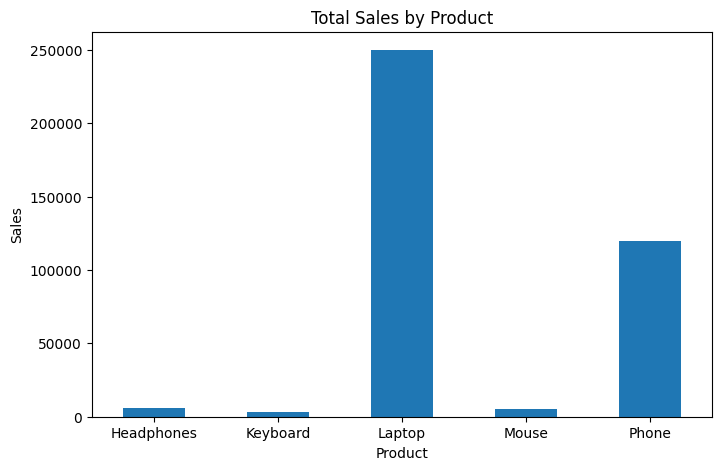

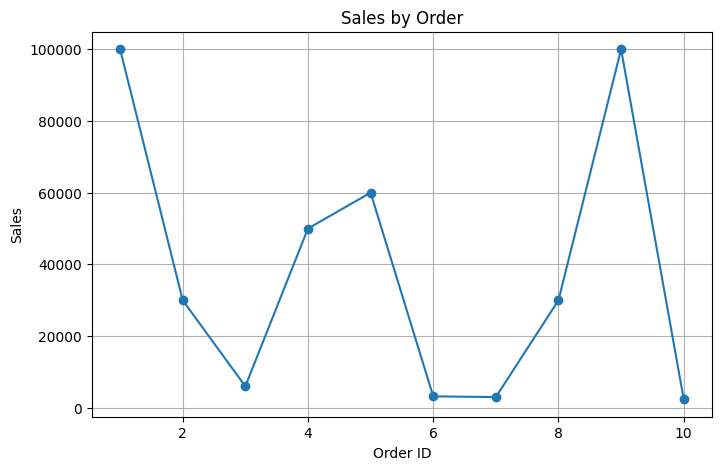

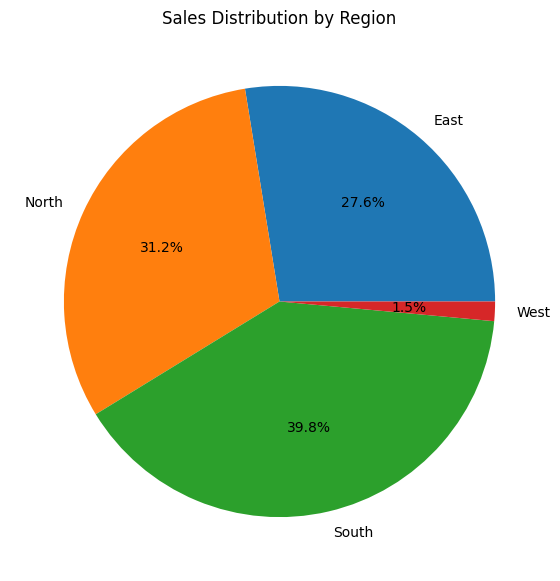

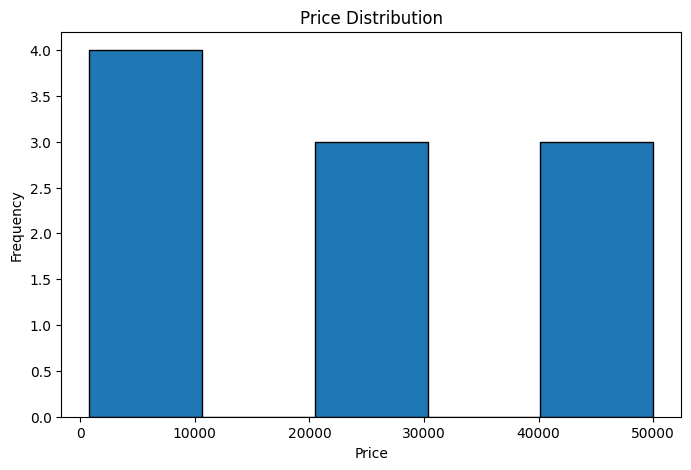

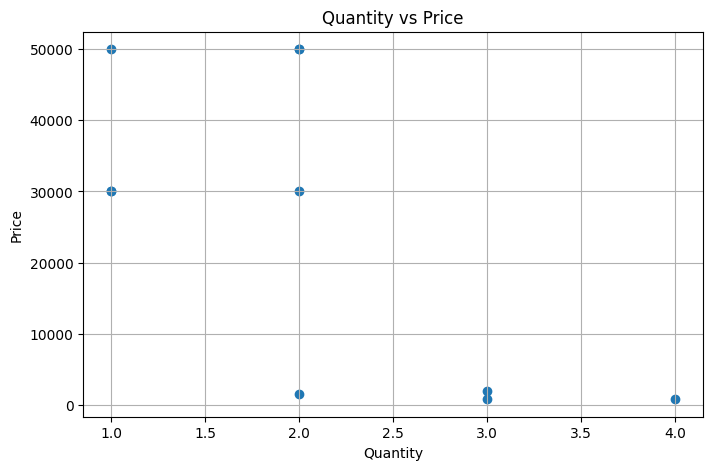

In [6]:
# TASK 3 - data visualization

import matplotlib.pyplot as plt

# 1. bar chart
product_sales = df.groupby("Product")["Sales"].sum()

plt.figure(figsize=(8,5))
product_sales.plot(kind="bar")
plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.show()

# 2. line chart
plt.figure(figsize=(8,5))
plt.plot(df["Order_ID"], df["Sales"], marker="o")
plt.title("Sales by Order")
plt.xlabel("Order ID")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

# 3. pie chart
region_sales = df.groupby("Region")["Sales"].sum()

plt.figure(figsize=(7,7))
plt.pie(region_sales, labels=region_sales.index, autopct="%1.1f%%")
plt.title("Sales Distribution by Region")
plt.show()

# 4. histogram
plt.figure(figsize=(8,5))
plt.hist(df["Price"], bins=5, edgecolor="black")
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

# 5. scatter plot
plt.figure(figsize=(8,5))
plt.scatter(df["Quantity"], df["Price"])
plt.title("Quantity vs Price")
plt.xlabel("Quantity")
plt.ylabel("Price")
plt.grid(True)
plt.show()

In [7]:
print("KEY INSIGHTS")
print("1. Laptop generated the highest total sales.")
print("2. South region generated the highest sales.")
print("3. Mouse had the highest quantity sold.")
print("4. No price outliers were detected using the IQR method.")
print("5. Quantity and Price had a negative correlation (-0.67) in this small sample; this does not mean one causes the other.")

KEY INSIGHTS
1. Laptop generated the highest total sales.
2. South region generated the highest sales.
3. Mouse had the highest quantity sold.
4. No price outliers were detected using the IQR method.
5. Quantity and Price had a negative correlation (-0.67) in this small sample; this does not mean one causes the other.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "Customer_ID": range(101, 111),
    "Age": [25, 32, 40, 28, 35, 45, 20, 29, 38, 33],
    "Gender": ["Male", "Female", "Male", "Female", "Male",
               "Female", "Male", "Male", "Female", "Male"],
    "Location": ["Bengaluru", "Chennai", "Mysuru", "Bengaluru",
                 "Chennai", "Chennai", "Bengaluru", "Bengaluru",
                 "Mysuru", "Chennai"],
    "Purchase_Amount": [2000, 5000, 7000, 3000, 6000,
                        8500, 2100, 2500, 8100, 3900],
    "Purchase_Frequency": [3, 5, 4, 2, 6, 8, 2, 3, 6, 4]
}

df4 = pd.DataFrame(data)

print("Customer dataset created successfully!")
display(df4)

Customer dataset created successfully!


,Customer_ID,Age,Gender,Location,Purchase_Amount,Purchase_Frequency
0,101,25,Male,Bengaluru,2000,3
1,102,32,Female,Chennai,5000,5
2,103,40,Male,Mysuru,7000,4
3,104,28,Female,Bengaluru,3000,2
4,105,35,Male,Chennai,6000,6
5,106,45,Female,Chennai,8500,8
6,107,20,Male,Bengaluru,2100,2
7,108,29,Male,Bengaluru,2500,3
8,109,38,Female,Mysuru,8100,6
9,110,33,Male,Chennai,3900,4


In [9]:
# Display basic information about the customer dataset
print("CUSTOMER DATASET INFORMATION")
print(df4.info())

# Display descriptive statistics
print("\nDESCRIPTIVE STATISTICS")
display(df4.describe())

# Display average customer age
print("\nAverage Customer Age:")
print(df4["Age"].mean())

# Display average purchase amount
print("\nAverage Purchase Amount:")
print(df4["Purchase_Amount"].mean())

CUSTOMER DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Customer_ID         10 non-null     int64 
 1   Age                 10 non-null     int64 
 2   Gender              10 non-null     object
 3   Location            10 non-null     object
 4   Purchase_Amount     10 non-null     int64 
 5   Purchase_Frequency  10 non-null     int64 
dtypes: int64(4), object(2)
memory usage: 612.0+ bytes
None

DESCRIPTIVE STATISTICS


,Customer_ID,Age,Purchase_Amount,Purchase_Frequency
count,10.00000,10.000000,10.000000,10.000000
mean,105.50000,32.500000,4810.000000,4.300000
std,3.02765,7.412452,2480.344958,1.946507
min,101.00000,20.000000,2000.000000,2.000000
25%,103.25000,28.250000,2625.000000,3.000000
50%,105.50000,32.500000,4450.000000,4.000000
75%,107.75000,37.250000,6750.000000,5.750000
max,110.00000,45.000000,8500.000000,8.000000



Average Customer Age:
32.5

Average Purchase Amount:
4810.0


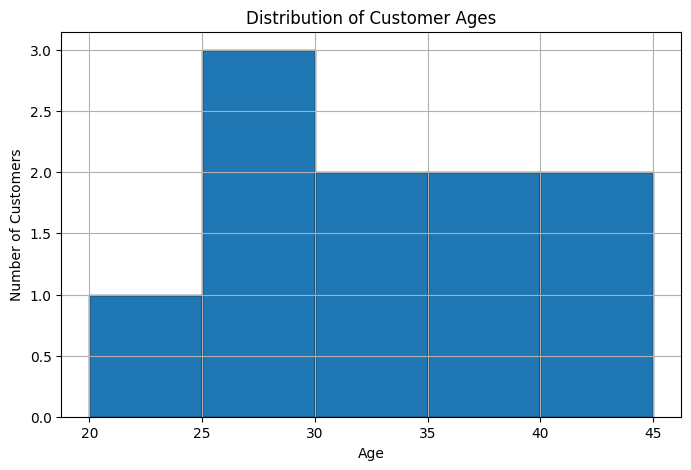

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the distribution of customer ages
plt.figure(figsize=(8, 5))
plt.hist(df4["Age"], bins=5, edgecolor="black")

plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.grid(True)
plt.show()

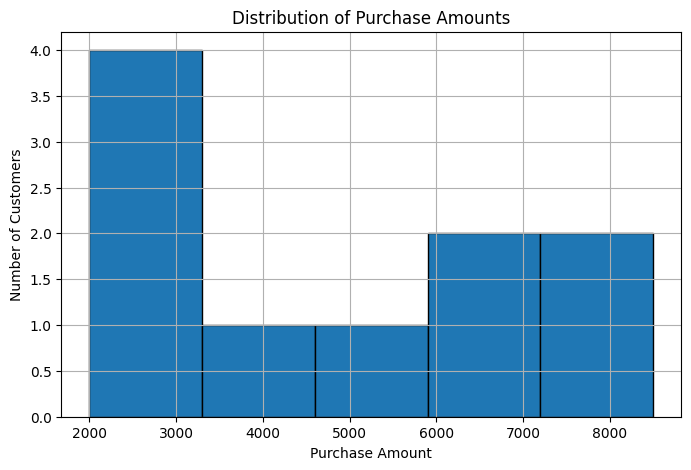

In [11]:
# Visualize customer purchase amounts
plt.figure(figsize=(8, 5))

plt.hist(df4["Purchase_Amount"], bins=5, edgecolor="black")

plt.title("Distribution of Purchase Amounts")
plt.xlabel("Purchase Amount")
plt.ylabel("Number of Customers")
plt.grid(True)
plt.show()

TOTAL PURCHASE AMOUNT BY LOCATION


,Purchase_Amount
Location,
Bengaluru,9600
Chennai,23400
Mysuru,15100


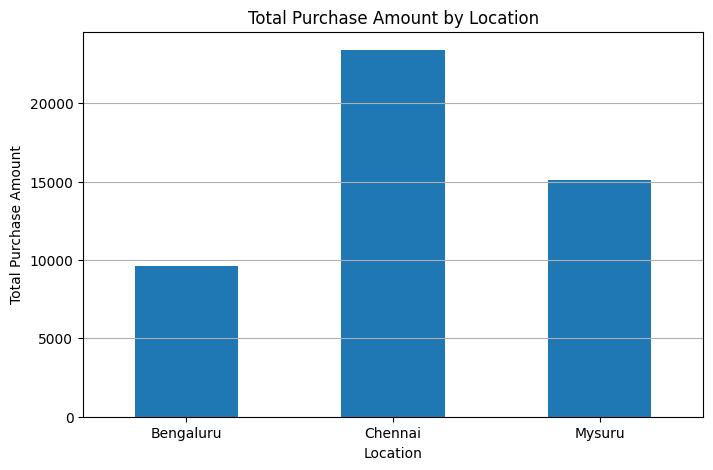

In [12]:
# Compare total purchase amounts across locations
location_sales = df4.groupby("Location")["Purchase_Amount"].sum()

print("TOTAL PURCHASE AMOUNT BY LOCATION")
display(location_sales)

plt.figure(figsize=(8, 5))
location_sales.plot(kind="bar")

plt.title("Total Purchase Amount by Location")
plt.xlabel("Location")
plt.ylabel("Total Purchase Amount")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

## Task 4 — Customer Data Analysis (additional project)



**Objective:** To study customer purchasing behaviour based on age, location, spending and purchase frequency.

**Dataset:** I used a sample dataset of 10 customers to practise analysing customer behaviour.


In [13]:
# 1. Check data quality and prepare analysis columns
customer_df = df4.copy()

required_columns = ["Customer_ID", "Age", "Gender", "Location", "Purchase_Amount", "Purchase_Frequency"]
missing_columns = [col for col in required_columns if col not in customer_df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

customer_df["Age"] = pd.to_numeric(customer_df["Age"], errors="coerce")
customer_df["Purchase_Amount"] = pd.to_numeric(customer_df["Purchase_Amount"], errors="coerce")
customer_df["Purchase_Frequency"] = pd.to_numeric(customer_df["Purchase_Frequency"], errors="coerce")
customer_df = customer_df.dropna(subset=["Customer_ID", "Age", "Location", "Purchase_Amount", "Purchase_Frequency"])
customer_df["Location"] = customer_df["Location"].astype(str).str.strip().str.title()
customer_df["Gender"] = customer_df["Gender"].astype(str).str.strip().str.title()

print(f"Customers included in analysis: {len(customer_df)}")
print("Missing values after preparation:")
display(customer_df[required_columns].isna().sum().to_frame("Missing values"))


Customers included in analysis: 10
Missing values after preparation:


,Missing values
Customer_ID,0
Age,0
Gender,0
Location,0
Purchase_Amount,0
Purchase_Frequency,0


In [14]:
# 2. Segment customers by spending using sample-data tertiles
# qcut creates relative low/medium/high groups for this dataset.
# If values tie too much for three groups, duplicates='drop' safely reduces the number of bins.
customer_df["Spending_Segment"] = pd.qcut(
    customer_df["Purchase_Amount"].rank(method="first"),
    q=3, labels=["Low Spender", "Medium Spender", "High Spender"]
)

# Segment age into readable life-stage bands (descriptive only, not assumptions about behavior).
customer_df["Age_Group"] = pd.cut(
    customer_df["Age"], bins=[0, 25, 35, 45, float("inf")],
    labels=["25 or younger", "26–35", "36–45", "46+"], include_lowest=True
)

print("CUSTOMER SEGMENTS")
display(customer_df[["Customer_ID", "Age", "Location", "Purchase_Amount", "Purchase_Frequency", "Spending_Segment", "Age_Group"]].sort_values("Purchase_Amount", ascending=False))


CUSTOMER SEGMENTS


,Customer_ID,Age,Location,Purchase_Amount,Purchase_Frequency,Spending_Segment,Age_Group
5,106,45,Chennai,8500,8,High Spender,36–45
8,109,38,Mysuru,8100,6,High Spender,36–45
2,103,40,Mysuru,7000,4,High Spender,36–45
4,105,35,Chennai,6000,6,High Spender,26–35
1,102,32,Chennai,5000,5,Medium Spender,26–35
9,110,33,Chennai,3900,4,Medium Spender,26–35
3,104,28,Bengaluru,3000,2,Medium Spender,26–35
7,108,29,Bengaluru,2500,3,Low Spender,26–35
6,107,20,Bengaluru,2100,2,Low Spender,25 or younger
0,101,25,Bengaluru,2000,3,Low Spender,25 or younger


In [15]:
# 3. Compare spending segments and find valuable customer groups
segment_summary = customer_df.groupby("Spending_Segment", observed=False).agg(
    Customer_Count=("Customer_ID", "nunique"),
    Total_Spending=("Purchase_Amount", "sum"),
    Average_Spending=("Purchase_Amount", "mean"),
    Average_Purchase_Frequency=("Purchase_Frequency", "mean")
).reset_index()

segment_summary = segment_summary.sort_values("Total_Spending", ascending=False)
print("SPENDING SEGMENT SUMMARY (ranked by total spending)")
display(segment_summary.round(2))

location_summary = customer_df.groupby("Location").agg(
    Customer_Count=("Customer_ID", "nunique"),
    Total_Spending=("Purchase_Amount", "sum"),
    Average_Spending=("Purchase_Amount", "mean"),
    Average_Purchase_Frequency=("Purchase_Frequency", "mean")
).reset_index().sort_values("Total_Spending", ascending=False)
print("LOCATION SUMMARY (ranked by total spending)")
display(location_summary.round(2))

# Most valuable by total spend is explicitly defined here; other definitions can yield a different group.
top_segment = segment_summary.iloc[0]
top_location = location_summary.iloc[0]
print(f"Highest-total-spending segment: {top_segment['Spending_Segment']} (total = {top_segment['Total_Spending']:.0f}; customers = {int(top_segment['Customer_Count'])})")
print(f"Highest-total-spending location: {top_location['Location']} (total = {top_location['Total_Spending']:.0f}; customers = {int(top_location['Customer_Count'])})")


SPENDING SEGMENT SUMMARY (ranked by total spending)


,Spending_Segment,Customer_Count,Total_Spending,Average_Spending,Average_Purchase_Frequency
2,High Spender,4,29600,7400.00,6.00
1,Medium Spender,3,11900,3966.67,3.67
0,Low Spender,3,6600,2200.00,2.67


LOCATION SUMMARY (ranked by total spending)


,Location,Customer_Count,Total_Spending,Average_Spending,Average_Purchase_Frequency
1,Chennai,4,23400,5850.0,5.75
2,Mysuru,2,15100,7550.0,5.00
0,Bengaluru,4,9600,2400.0,2.50


Highest-total-spending segment: High Spender (total = 29600; customers = 4)
Highest-total-spending location: Chennai (total = 23400; customers = 4)


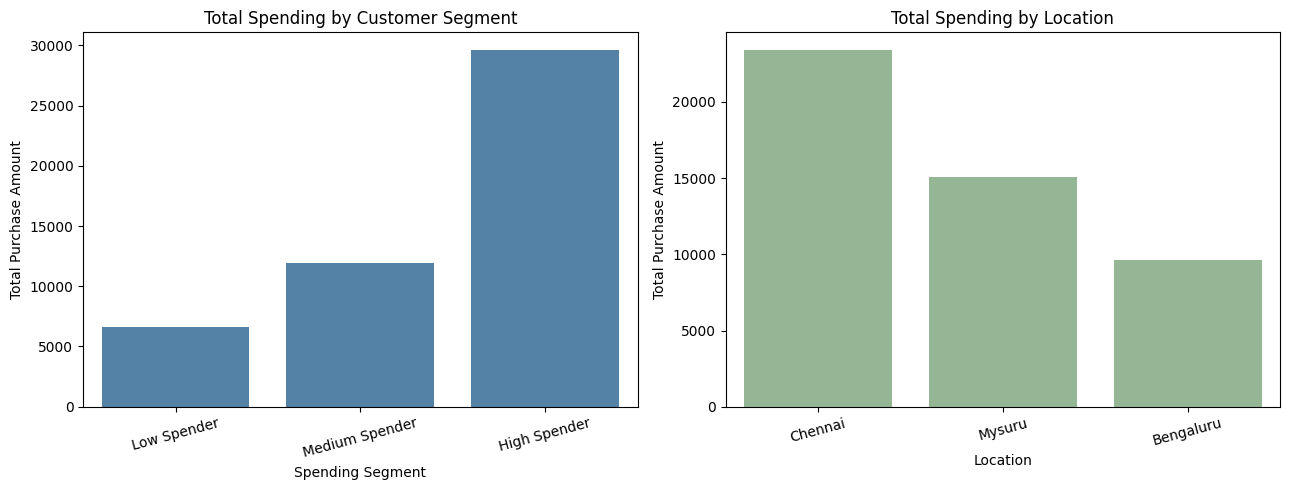

In [16]:
# 4. Visual reports: spending by segment and location
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

segment_plot = segment_summary.sort_values("Spending_Segment")
sns.barplot(data=segment_plot, x="Spending_Segment", y="Total_Spending", ax=axes[0], color="steelblue")
axes[0].set_title("Total Spending by Customer Segment")
axes[0].set_xlabel("Spending Segment")
axes[0].set_ylabel("Total Purchase Amount")
axes[0].tick_params(axis="x", rotation=15)

loc_plot = location_summary.sort_values("Total_Spending", ascending=False)
sns.barplot(data=loc_plot, x="Location", y="Total_Spending", ax=axes[1], color="darkseagreen")
axes[1].set_title("Total Spending by Location")
axes[1].set_xlabel("Location")
axes[1].set_ylabel("Total Purchase Amount")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


In [17]:
# 5. Age group comparison and customer-level view
age_summary = customer_df.groupby("Age_Group", observed=False).agg(
    Customer_Count=("Customer_ID", "nunique"),
    Total_Spending=("Purchase_Amount", "sum"),
    Average_Spending=("Purchase_Amount", "mean")
).reset_index()
print("AGE GROUP SUMMARY")
display(age_summary.round(2))

print("TOP CUSTOMERS BY PURCHASE AMOUNT (sample dataset)")
display(customer_df.nlargest(5, "Purchase_Amount")[["Customer_ID", "Age", "Location", "Purchase_Amount", "Purchase_Frequency", "Spending_Segment"]])


AGE GROUP SUMMARY


,Age_Group,Customer_Count,Total_Spending,Average_Spending
0,25 or younger,2,4100,2050.00
1,26–35,5,20400,4080.00
2,36–45,3,23600,7866.67
3,46+,0,0,NaN


TOP CUSTOMERS BY PURCHASE AMOUNT (sample dataset)


,Customer_ID,Age,Location,Purchase_Amount,Purchase_Frequency,Spending_Segment
5,106,45,Chennai,8500,8,High Spender
8,109,38,Mysuru,8100,6,High Spender
2,103,40,Mysuru,7000,4,High Spender
4,105,35,Chennai,6000,6,High Spender
1,102,32,Chennai,5000,5,Medium Spender


### Business recommendations



- **High-spending customers:** Try offering loyalty rewards to encourage repeat purchases.
- **Purchase frequency:** Check whether offers can encourage customers to buy more often.
- **Location:** Compare sales across locations to understand where products are selling well.
- **Future analysis:** Use more customer records to check whether these patterns continue.

**Note:** This analysis uses only 10 sample customer records, so the findings may not represent actual customer behaviour.
